In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Network Traffic Analysis Project")
print("Libraries imported successfully!")


Network Traffic Analysis Project
Libraries imported successfully!


In [20]:

data = {
    "Duration": [
        1, 2, 1, 3, 2, 4, 1, 2, 3, 1,
        2, 3, 1, 4, 2, 1, 3, 2, 4, 1
    ],
    "Protocol": [
        "TCP", "TCP", "UDP", "TCP", "UDP",
        "TCP", "TCP", "UDP", "TCP", "TCP",
        "UDP", "TCP", "TCP", "UDP", "TCP",
        "UDP", "TCP", "UDP", "TCP", "TCP"
    ],
    "Destination_Port": [
        443, 80, 53, 443, 53, 80, 443, 53, 80, 443,
        53, 443, 80, 53, 443, 53, 80, 53, 443, 80
    ],
    "Bytes": [
        500, 800, 120, 900, 150, 700, 450, 130, 850, 480,
        140, 950, 750, 160, 520, 110, 820, 125, 980, 780
    ],
    "Packets": [
        5, 8, 2, 9, 3, 7, 4, 2, 8, 5,
        3, 10, 7, 2, 5, 2, 9, 3, 10, 8
    ],
    "Label": [
        "Normal", "Normal", "Normal", "Normal", "Normal",
        "Normal", "Normal", "Normal", "Normal", "Normal",
        "Normal", "Suspicious", "Suspicious", "Suspicious",
        "Suspicious", "Normal", "Suspicious", "Normal",
        "Suspicious", "Suspicious"
    ]
}

df = pd.DataFrame(data)

print("Dataset created!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset created!
Dataset shape: (20, 6)


,Duration,Protocol,Destination_Port,Bytes,Packets,Label
0,1,TCP,443,500,5,Normal
1,2,TCP,80,800,8,Normal
2,1,UDP,53,120,2,Normal
3,3,TCP,443,900,9,Normal
4,2,UDP,53,150,3,Normal


In [21]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTraffic labels:")
print(df["Label"].value_counts())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Duration          20 non-null     int64
 1   Protocol          20 non-null     str  
 2   Destination_Port  20 non-null     int64
 3   Bytes             20 non-null     int64
 4   Packets           20 non-null     int64
 5   Label             20 non-null     str  
dtypes: int64(4), str(2)
memory usage: 1.3 KB

Missing values:
Duration            0
Protocol            0
Destination_Port    0
Bytes               0
Packets             0
Label               0
dtype: int64

Traffic labels:
Label
Normal        13
Suspicious     7
Name: count, dtype: int64


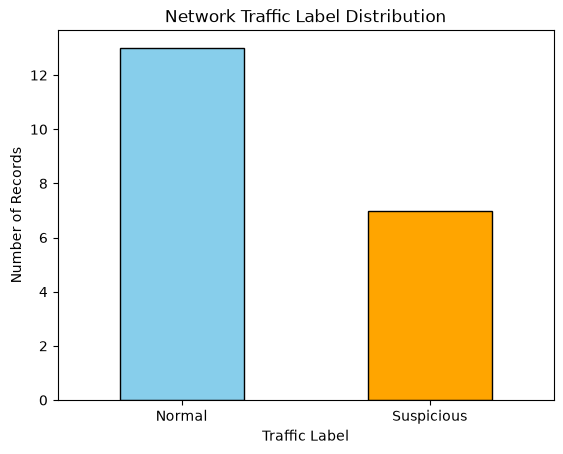

In [22]:

df["Label"].value_counts().plot(
    kind="bar",
    color=["skyblue", "orange"],
    edgecolor="black"
)

plt.title("Network Traffic Label Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()


In [23]:

protocol_map = {
    "TCP": 0,
    "UDP": 1,
    "ICMP": 2
}

df["Protocol_Code"] = df["Protocol"].map(protocol_map)

display(df[["Protocol", "Protocol_Code"]].head())


,Protocol,Protocol_Code
0,TCP,0
1,TCP,0
2,UDP,1
3,TCP,0
4,UDP,1


In [24]:

features = [
    "Duration",
    "Protocol_Code",
    "Destination_Port",
    "Bytes",
    "Packets"
]

X = df[features]
y = df["Label"]

print("Features:", features)
print("Input shape:", X.shape)
print("Target shape:", y.shape)


Features: ['Duration', 'Protocol_Code', 'Destination_Port', 'Bytes', 'Packets']
Input shape: (20, 5)
Target shape: (20,)


In [25]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 15
Testing records: 5


In [26]:

model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")


Machine Learning model trained successfully!


In [27]:

y_pred = model.predict(X_test)

print("Actual labels:    ", y_test.to_numpy())
print("Predicted labels: ", y_pred)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")


Actual labels:     ['Normal' 'Normal' 'Suspicious' 'Suspicious' 'Normal']
Predicted labels:  ['Normal' 'Normal' 'Normal' 'Normal' 'Normal']
Accuracy: 60.0 %


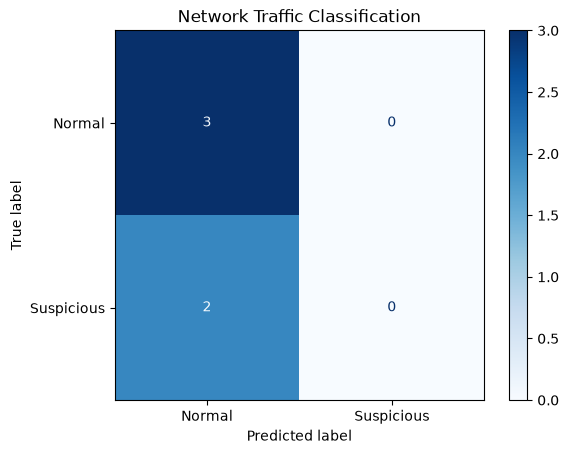

In [28]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Normal", "Suspicious"],
    cmap="Blues"
)

plt.title("Network Traffic Classification")
plt.show()


In [29]:

new_traffic = pd.DataFrame([{
    "Duration": 2,
    "Protocol_Code": 0,
    "Destination_Port": 443,
    "Bytes": 600,
    "Packets": 6
}])

prediction = model.predict(new_traffic[features])[0]

print("Predicted traffic category:", prediction)


Predicted traffic category: Suspicious
